# Evaluación del modelo YOLOv8n-seg — clasificación varietal de café

Este notebook tiene un solo propósito: **medir qué tan bien quedó el modelo ya entrenado**.
No entrena nada, no segmenta fotos nuevas y no tiene interfaz — para eso está la aplicación
de Streamlit (`06_aplicacion_demo/app.py`).

Aquí obtienes:

1. Las métricas globales del modelo (precisión, exhaustividad, mAP50, mAP50-95).
2. Las métricas desglosadas por variedad, listas para exportar a tabla.
3. Las matrices de confusión (absoluta y normalizada).
4. Las curvas de evaluación (F1, precisión-exhaustividad) para caja y máscara.
5. Los valores de referencia de color, forma y textura por variedad, calculados a partir
   del `descriptores_por_hoja_v2.csv` que genera `extraer_morfologia_v2.py`.

**Orden de ejecución:** de arriba hacia abajo, sin saltarte celdas. Cada celda depende de la anterior.

---
## Paso 1 — Preparar el entorno

Estas celdas se corren una sola vez por sesión de Colab.

In [1]:
# Celda 1 — Conectar con Google Drive
# Aquí es donde tienes guardado el modelo entrenado, el data.yaml y el CSV de descriptores.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Celda 2 — Instalar las librerías necesarias
# Se instalan de nuevo cada vez porque Colab borra todo al reiniciar la sesión.
!pip install ultralytics scikit-image scikit-learn openpyxl -q
print("Listo. Librerías instaladas.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.8/45.8 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.4/65.4 kB 5.4 MB/s eta 0:00:00
Listo. Librerías instaladas.


In [3]:
# Celda 3 — Importar lo que se usa en este notebook
import os
import sys
import yaml
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from PIL import Image
from ultralytics import YOLO

print("Listo. Imports completados.")

Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
Listo. Imports completados.


In [4]:
# Celda 4 — Configura aquí tus rutas antes de correr el resto del notebook

# Ruta al modelo ya entrenado (el .pt que te generó el notebook de entrenamiento)
BEST_MODEL = "/content/drive/MyDrive/Dataset_Augmentation_Balanceado/modelos_entrenados/best_cafe_yolov8_seg.pt"

# CSV con los descriptores morfológicos del dataset BASE (sin aumentar).
# Lo genera extraer_morfologia_v2.py y debe ser la versión v2: sus descriptores
# de textura usan 32 niveles de gris y excluyen el fondo de la máscara, así que
# NO son comparables con los de una versión anterior. Si subes el CSV equivocado,
# el notebook lo va a detectar solo en la Celda 7 (verificación de coherencia).
RUTA_CSV_BASE = "/content/drive/MyDrive/Dataset_Augmentation_Balanceado/descriptores_por_hoja_v2.csv"

# Carpeta de Drive donde subiste descriptores_v2.py (el módulo con las funciones
# de color, forma y textura). Debe ser la misma carpeta donde tienes el CSV.
CARPETA_MODULOS = "/content/drive/MyDrive/Dataset_Augmentation_Balanceado"

# Archivo data.yaml del dataset, necesario para que el modelo sepa dónde están
# las imágenes y las etiquetas reales de validación/prueba.
DATA_YAML = "/content/drive/MyDrive/Dataset_Augmentation_Balanceado/data.yaml"

# Carpeta donde se guardan las tablas de métricas que exporta este notebook.
CARPETA_RESULTADOS = "/content/drive/MyDrive/Dataset_Augmentation_Balanceado/resultados_evaluacion"

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

print("Configuración cargada.")
print(f"  Modelo:   {os.path.basename(BEST_MODEL)}")
print(f"  CSV base: {os.path.basename(RUTA_CSV_BASE)}")

Configuración cargada.
  Modelo:   best_cafe_yolov8_seg.pt
  CSV base: descriptores_por_hoja_v2.csv


In [5]:
# Celda 5 — Importar las funciones del módulo compartido
# Solo necesito dos funciones aquí: ajustar_gmms (para calcular los valores de
# referencia de color/forma/textura) y verificar_coherencia (para confirmar que
# el CSV cargado es la versión correcta). El resto de funciones del módulo
# (calcular_color, calcular_forma, calcular_textura) las usa la app de
# Streamlit para procesar hojas nuevas; este notebook no las necesita porque
# no segmenta imágenes, solo evalúa el modelo ya entrenado.

if CARPETA_MODULOS not in sys.path:
    sys.path.append(CARPETA_MODULOS)

try:
    from descriptores_v2 import ajustar_gmms, verificar_coherencia
    print("Módulo descriptores_v2 importado correctamente.")
except ModuleNotFoundError:
    raise SystemExit(
        f"No se encontró descriptores_v2.py en {CARPETA_MODULOS}.\n"
        "Súbelo a esa carpeta de Drive y vuelve a correr esta celda.")

Módulo descriptores_v2 importado correctamente.


In [6]:
# Celda 6 — Cargar el CSV base y calcular los valores de referencia (color, forma, textura)
# Estos valores son los que traducen un número (por ejemplo, contraste = 27.8)
# en una categoría interpretable (por ejemplo, "Rugosa"). Se calculan una sola
# vez sobre el conjunto base y sirven como marco de referencia fijo.

df_morfologia = pd.read_csv(RUTA_CSV_BASE)

# Antes de seguir, confirma que este CSV es la versión v2 y no una anterior.
# Si mezclas versiones, las categorías salen mal sin ningún mensaje de error.
ok, mensaje = verificar_coherencia(df_morfologia)
print(mensaje)
if not ok:
    raise SystemExit("El CSV base no corresponde a la versión v2. Corrige RUTA_CSV_BASE en la Celda 4.")

GMMS = ajustar_gmms(df_morfologia)

print("\nValores de referencia por característica morfológica:\n")
for caracteristica, modelo in GMMS.items():
    medias = modelo["gmm"].means_.flatten()[modelo["orden"]]
    pesos = modelo["gmm"].weights_[modelo["orden"]]
    print(f"  {caracteristica.upper()}  (columna '{modelo['columna']}')")
    for i, nivel in enumerate(modelo["niveles"]):
        print(f"     {nivel:<20} media={medias[i]:8.2f}   peso={pesos[i]:.2f}")
    print()

CSV v2 verificado: 2611 hojas, contraste mediano 20.54.

Valores de referencia por característica morfológica:

  COLOR  (columna 'H')
     Verde amarillento    media=   26.95   peso=0.15
     Verde claro          media=   39.61   peso=0.64
     Verde oscuro         media=   47.17   peso=0.21

  FORMA  (columna 'aspect_ratio')
     Redondeada           media=    1.53   peso=0.24
     Elíptica             media=    2.52   peso=0.57
     Alargada             media=    3.54   peso=0.19

  TEXTURA  (columna 'contrast')
     Lisa                 media=   15.44   peso=0.49
     Coriácea             media=   25.59   peso=0.38
     Rugosa               media=   38.19   peso=0.13



In [7]:
# Celda 7 — Cargar el modelo YOLOv8n-seg ya entrenado
model_pred = YOLO(BEST_MODEL)
print("Modelo cargado desde:", BEST_MODEL)
print("Variedades que reconoce:", model_pred.names)

Modelo cargado desde: /content/drive/MyDrive/Dataset_Augmentation_Balanceado/modelos_entrenados/best_cafe_yolov8_seg.pt
Variedades que reconoce: {0: 'Bourbon', 1: 'Castillo', 2: 'Geisha', 3: 'Mundonovo', 4: 'SanSalvador', 5: 'Sarchimor', 6: 'Typica'}


---
## Paso 2 — Evaluar el modelo (métricas, gráficas y matrices)

Aquí es donde se generan las cifras y figuras que van directo al capítulo de Resultados.
La evaluación se hace contra las etiquetas reales del conjunto `test`, que el modelo
nunca vio durante el entrenamiento.

In [8]:
# Celda 8 — Verificar que data.yaml apunta a las carpetas correctas antes de evaluar
# Este chequeo evita perder tiempo si alguna ruta del data.yaml quedó mal
# configurada: te dice de inmediato si la carpeta existe y cuántas imágenes tiene.

with open(DATA_YAML, "r", encoding="utf-8") as f:
    contenido_yaml = yaml.safe_load(f)

print("Contenido de data.yaml:")
print(contenido_yaml)

base_dir = os.path.dirname(DATA_YAML)
for clave in ["train", "val", "test"]:
    if clave in contenido_yaml:
        ruta_declarada = contenido_yaml[clave]
        ruta_absoluta = (ruta_declarada if os.path.isabs(ruta_declarada)
                         else os.path.join(base_dir, ruta_declarada))
        existe = os.path.isdir(ruta_absoluta)
        n_imagenes = len(os.listdir(ruta_absoluta)) if existe else 0
        print(f"\n{clave}: declarado como '{ruta_declarada}'")
        print(f"  -> ruta resuelta: {ruta_absoluta}")
        print(f"  -> ¿existe la carpeta? {existe}")
        print(f"  -> nro. de archivos encontrados: {n_imagenes}")

Contenido de data.yaml:
{'path': '/content/drive/MyDrive/Dataset_Augmentation_Balanceado', 'train': 'train/images', 'val': 'valid/images', 'test': 'test/images', 'nc': 7, 'names': {0: 'Bourbon', 1: 'Castillo', 2: 'Geisha', 3: 'Mundonovo', 4: 'SanSalvador', 5: 'Sarchimor', 6: 'Typica'}}

train: declarado como 'train/images'
  -> ruta resuelta: /content/drive/MyDrive/Dataset_Augmentation_Balanceado/train/images
  -> ¿existe la carpeta? True
  -> nro. de archivos encontrados: 3819

val: declarado como 'valid/images'
  -> ruta resuelta: /content/drive/MyDrive/Dataset_Augmentation_Balanceado/valid/images
  -> ¿existe la carpeta? True
  -> nro. de archivos encontrados: 468

test: declarado como 'test/images'
  -> ruta resuelta: /content/drive/MyDrive/Dataset_Augmentation_Balanceado/test/images
  -> ¿existe la carpeta? True
  -> nro. de archivos encontrados: 231


In [9]:
# Celda 9 — Correr la evaluación y obtener las métricas globales
# IMPORTANTE: no se pasa el parámetro conf aquí, para que Ultralytics use su
# umbral por defecto (0.001) y recorra la curva completa de precisión y
# exhaustividad. Esto es lo que necesitas para el mAP de las Tablas 14-15.
# El umbral operativo (conf=0.25) solo se usa más adelante, en la Celda 12,
# para las matrices de confusión — son dos preguntas distintas y cada una
# necesita su propio umbral.

SPLIT_EVALUACION = "test"

metricas = model_pred.val(data=DATA_YAML, split=SPLIT_EVALUACION)

print("\n" + "=" * 60)
print(f"MÉTRICAS GLOBALES — split '{SPLIT_EVALUACION}'")
print("=" * 60)
print("  --- Caja delimitadora (Box) ---")
print(f"  Precisión (P):  {metricas.box.mp:.4f}")
print(f"  Recall (R):     {metricas.box.mr:.4f}")
print(f"  mAP50:          {metricas.box.map50:.4f}")
print(f"  mAP50-95:       {metricas.box.map:.4f}")
print("  --- Máscara de segmentación (Mask) ---")
print(f"  Precisión (P):  {metricas.seg.mp:.4f}")
print(f"  Recall (R):     {metricas.seg.mr:.4f}")
print(f"  mAP50:          {metricas.seg.map50:.4f}")
print(f"  mAP50-95:       {metricas.seg.map:.4f}")
print("=" * 60)
print(f"\nGráficas y matrices guardadas en: {metricas.save_dir}")

Ultralytics 8.4.129 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLOv8n-seg summary (fused): 86 layers, 3,259,429 parameters, 0 gradients, 11.3 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 1.8±1.8 ms, read: 9.3±20.6 MB/s, size: 77.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/.shortcut-targets-by-id/1PWQxGLGw_myv-Lh3rvCPbcK18wX7rHaR/Dataset_Augmentation_Balanceado/test/labels.cache... 231 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 231/231 31.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 7.0s/it 1:45
                   all        231        264      0.941      0.919      0.968      0.937      0.941      0.919      0.967      0.957
               Bourbon         42         48      0.911      0.896    

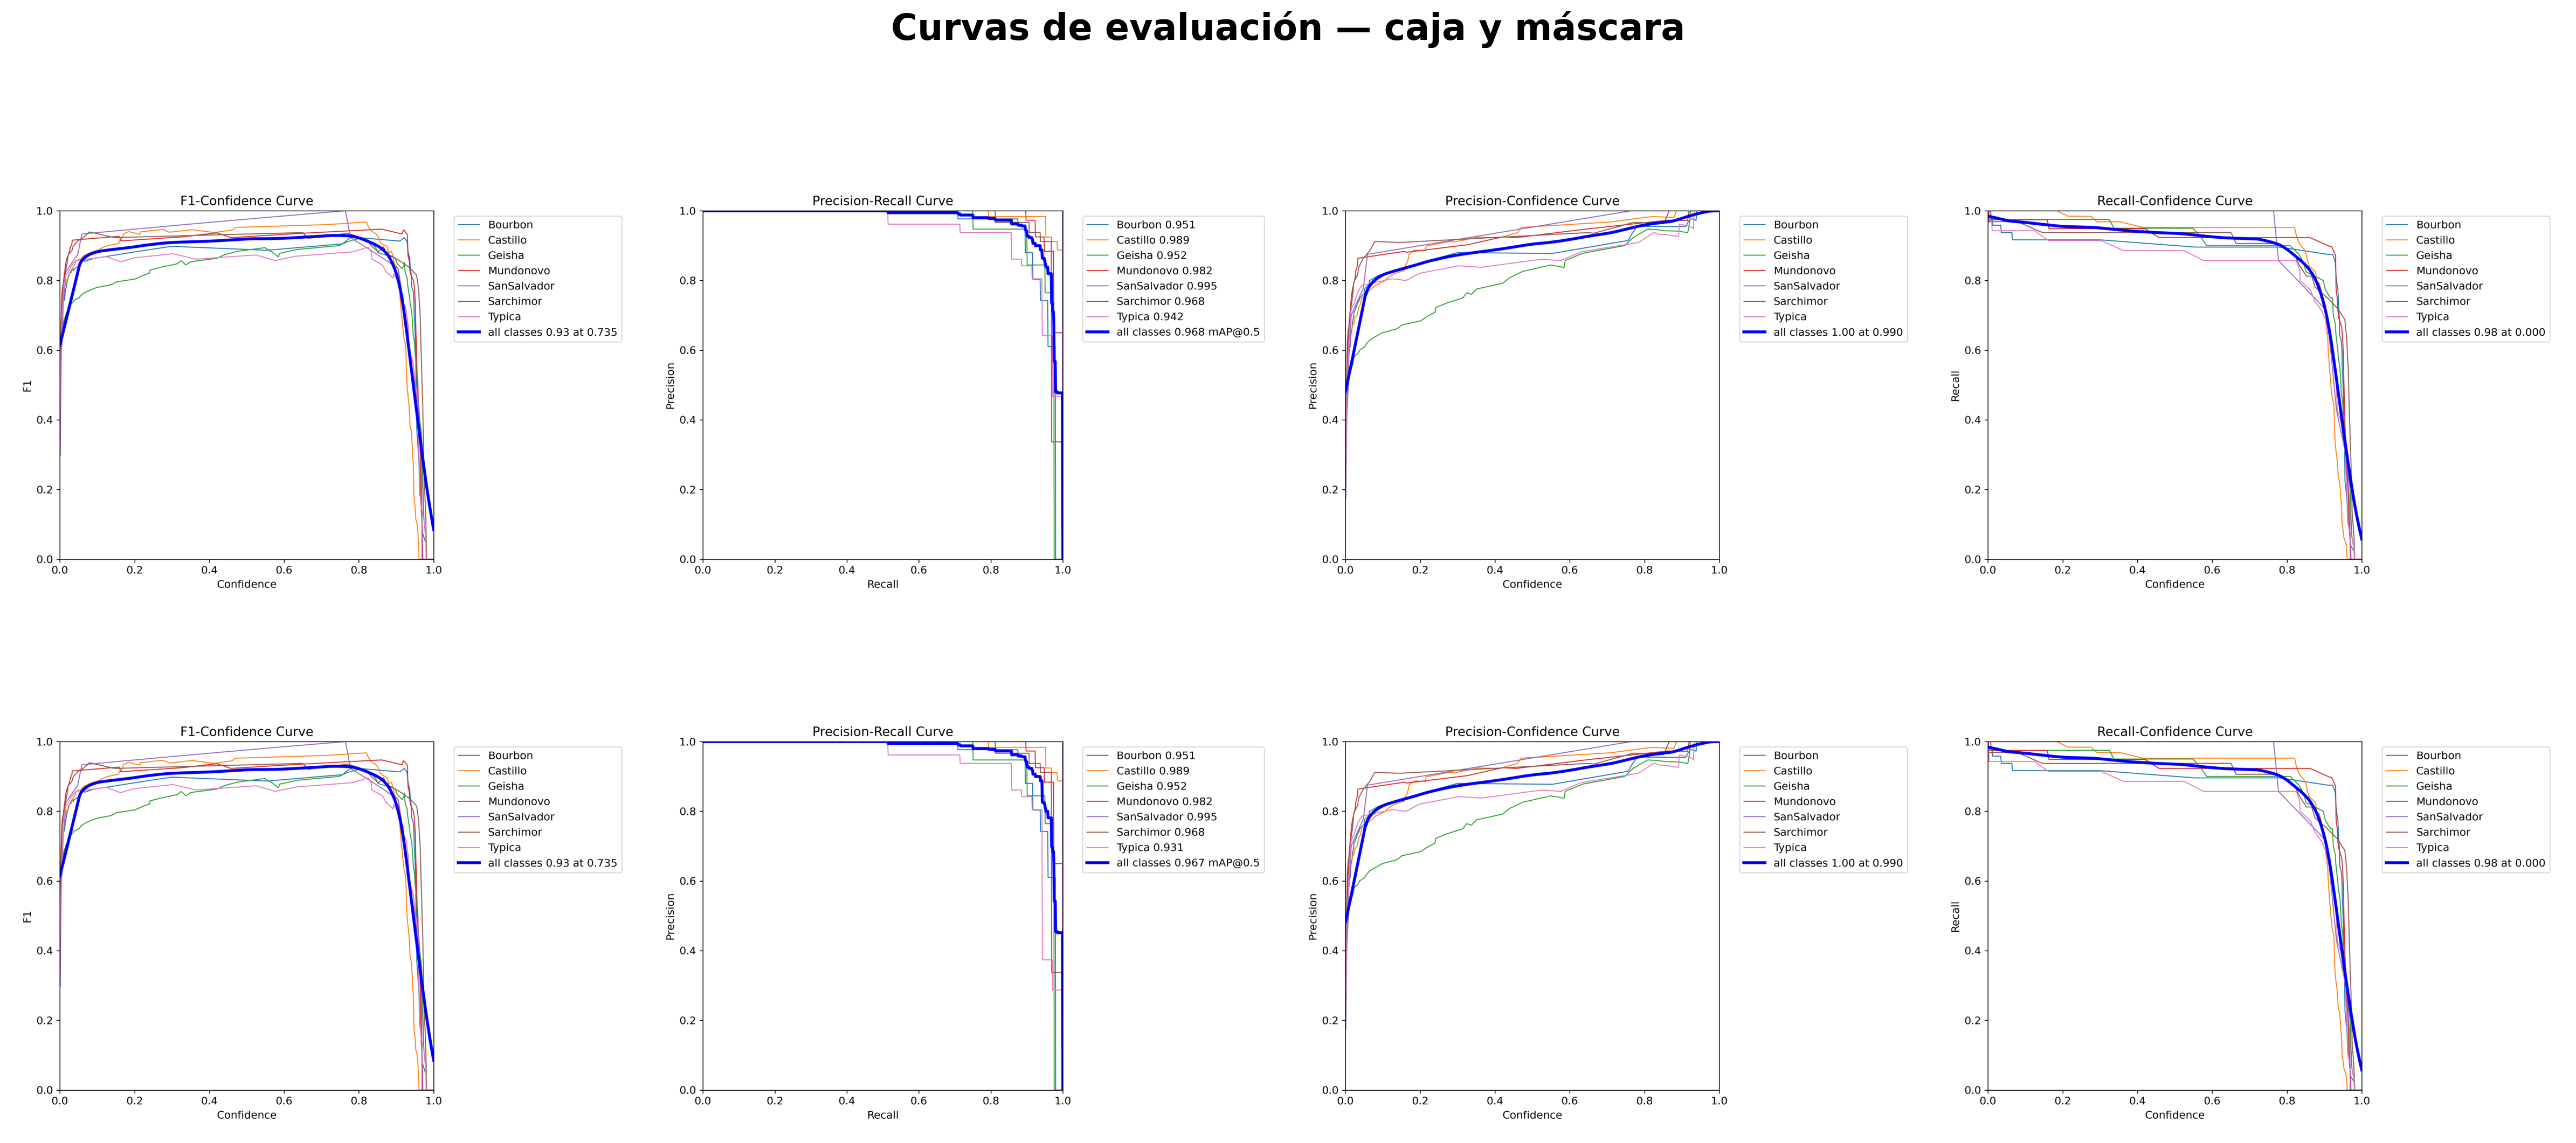


Gráfica combinada guardada en: /content/runs/segment/val/curvas_combinadas.png


In [10]:
# Celda 10 — Combinar las ocho curvas de evaluación en una sola imagen
# Ultralytics ya genera cada curva por separado (F1, PR, P, R, para caja y
# para máscara). Aquí solo las junto en una cuadrícula 2x4 para tener una
# única figura de referencia rápida, en vez de ocho archivos sueltos.

ruta_val = metricas.save_dir

archivos = [
    ["BoxF1_curve.png", "BoxPR_curve.png", "BoxP_curve.png", "BoxR_curve.png"],
    ["MaskF1_curve.png", "MaskPR_curve.png", "MaskP_curve.png", "MaskR_curve.png"],
]

fig, axes = plt.subplots(2, 4, figsize=(24, 12), dpi=200)
fig.suptitle("Curvas de evaluación — caja y máscara", fontsize=24, fontweight="bold", y=0.98)

for i, fila in enumerate(archivos):
    for j, archivo in enumerate(fila):
        ruta_img = os.path.join(ruta_val, archivo)
        ax = axes[i, j]
        if os.path.exists(ruta_img):
            ax.imshow(Image.open(ruta_img))
        else:
            ax.text(0.5, 0.5, f"Archivo no encontrado:\n{archivo}", ha="center", va="center", fontsize=12)
        ax.axis("off")

plt.tight_layout()
ruta_guardado = os.path.join(ruta_val, "curvas_combinadas.png")
plt.savefig(ruta_guardado, bbox_inches="tight")
plt.show()

print(f"\nGráfica combinada guardada en: {ruta_guardado}")

In [11]:
# Celda 11 — Armar la tabla de métricas por variedad
# Esta es la tabla que va directo a la sección de Resultados (equivalente a
# tu Tabla 15): una fila por variedad, con precisión, exhaustividad y mAP
# tanto para caja como para máscara.

filas_metricas = []
for i, class_idx in enumerate(metricas.box.ap_class_index):
    filas_metricas.append({
        "Variedad": model_pred.names[int(class_idx)],
        "P (Box)": round(float(metricas.box.p[i]), 4),
        "R (Box)": round(float(metricas.box.r[i]), 4),
        "mAP50 (Box)": round(float(metricas.box.ap50[i]), 4),
        "mAP50-95 (Box)": round(float(metricas.box.ap[i]), 4),
        "mAP50 (Mask)": round(float(metricas.seg.ap50[i]), 4),
        "mAP50-95 (Mask)": round(float(metricas.seg.ap[i]), 4),
    })

df_metricas = pd.DataFrame(filas_metricas)

marca = datetime.now().strftime("%Y%m%d_%H%M%S")
ruta_metricas = os.path.join(CARPETA_RESULTADOS, f"metricas_por_variedad_{marca}.csv")
df_metricas.to_csv(ruta_metricas, index=False)
print(f"Tabla guardada en: {ruta_metricas}\n")

df_metricas

Tabla guardada en: /content/drive/MyDrive/Dataset_Augmentation_Balanceado/resultados_evaluacion/metricas_por_variedad_20260826_024027.csv



,Variedad,P (Box),R (Box),mAP50 (Box),mAP50-95 (Box),mAP50 (Mask),mAP50-95 (Mask)
0,Bourbon,0.9108,0.8958,0.9509,0.9374,0.9509,0.9483
1,Castillo,0.9714,0.9524,0.9887,0.9478,0.9887,0.9687
2,Geisha,0.8977,0.9000,0.9523,0.9219,0.9523,0.9352
3,Mundonovo,0.9582,0.9231,0.9822,0.9644,0.9822,0.9822
4,SanSalvador,0.9948,1.0000,0.9950,0.9950,0.9950,0.9950
5,Sarchimor,0.9562,0.9062,0.9676,0.9499,0.9676,0.9656
6,Typica,0.9005,0.8571,0.9424,0.8394,0.9307,0.9075


In [ ]:
# Celda 12 — Mostrar las matrices de confusión (Figuras 23 y 24 de la tesis)
# Estas SÍ se generan con el umbral de despliegue (conf=0.25, iou=0.5), a
# diferencia del mAP de la Celda 9. Por eso se vuelve a llamar a model.val()
# aquí, pasando explícitamente ese umbral: es el punto de operación real que
# usarías si desplegaras el modelo, y es lo que hace interpretable la matriz.

resultado_matrices = model_pred.val(data=DATA_YAML, split=SPLIT_EVALUACION,
                                     conf=0.25, iou=0.5, plots=True)

def mostrar_grafica(carpeta, nombre_archivo, titulo, figsize=(9, 9)):
    ruta = os.path.join(str(carpeta), nombre_archivo)
    if os.path.exists(ruta):
        plt.figure(figsize=figsize)
        plt.imshow(plt.imread(ruta))
        plt.axis("off")
        plt.title(titulo, fontsize=12)
        plt.show()
    else:
        print(f"No se encontró: {ruta}")


mostrar_grafica(resultado_matrices.save_dir, "confusion_matrix.png",
                "Matriz de confusión (valores absolutos) — Figura 23")

mostrar_grafica(resultado_matrices.save_dir, "confusion_matrix_normalized.png",
                "Matriz de confusión normalizada — Figura 24")

print(f"\nMatrices guardadas en: {resultado_matrices.save_dir}")

Ultralytics 8.4.129 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
val: Fast image access ✅ (ping: 0.5±0.0 ms, read: 85.2±21.2 MB/s, size: 93.1 KB)
val: Scanning /content/drive/.shortcut-targets-by-id/1PWQxGLGw_myv-Lh3rvCPbcK18wX7rHaR/Dataset_Augmentation_Balanceado/test/labels.cache... 231 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 231/231 48.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 26% ━━━───────── 4/15 9.2s/it 28.5s<1:41

---
## Resumen de lo que obtuviste al correr este notebook

- Métricas globales y por variedad (Celdas 9 y 11) → Tablas 14 y 15 de Resultados.
- Matrices de confusión (Celda 12) → Figuras 23 y 24 de Resultados.
- Curvas F1 y precisión-exhaustividad (Celda 10) → material de apoyo para justificar el
  umbral de confianza elegido en el despliegue.
- Valores de referencia de color, forma y textura (Celda 6) → base de la Tabla 10 y de la
  discretización cualitativa descrita en la Sección 6.2.5.

Para clasificar hojas nuevas (no las del dataset), usa la aplicación de Streamlit en
`06_aplicacion_demo/app.py` — ese es el flujo pensado para eso, con interfaz gráfica,
filtro de plausibilidad morfológica y exportación de resultados.